# **Projekt - TwitterEmo**


In [ ]:
%pip install datasets pandas matplotlib seaborn transformers scikit-learn torch accelerate -q

In [ ]:
from datasets import load_dataset

dataset = load_dataset("clarin-pl/twitteremo")

print(dataset)

README.md:   0%|          | 0.00/865 [00:00<?, ?B/s]

twitteremo_final.csv:   0%|          | 0.00/6.89M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/35921 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'data', 'tekst', 'radość', 'smutek', 'zaufanie', 'wstręt', 'strach', 'gniew', 'przeczuwanie', 'zdziwienie', 'pozytywny', 'negatywny', 'neutralny', 'ambiwalentny', 'sarkazm'],
        num_rows: 35921
    })
})


In [ ]:
print("Dostępne podziały:")
print(dataset.keys())

for split in dataset:
  print("\nNazwa podziału:", split)
  print("Liczba rekordów:", len(dataset[split]))
  print("Nazwy kolumn:", dataset[split].column_names)

  print("\nPrzykładowy rekord:")
  print(dataset[split][0])

Dostępne podziały:
dict_keys(['train'])

Nazwa podziału: train
Liczba rekordów: 35921
Nazwy kolumn: ['id', 'data', 'tekst', 'radość', 'smutek', 'zaufanie', 'wstręt', 'strach', 'gniew', 'przeczuwanie', 'zdziwienie', 'pozytywny', 'negatywny', 'neutralny', 'ambiwalentny', 'sarkazm']

Przykładowy rekord:
{'id': 0, 'data': '2021-09-02', 'tekst': '@anonymized_account jeszcze zaraz będzie rady ministrów i ministra spraw wewnętrznych', 'radość': 0, 'smutek': 0, 'zaufanie': 0, 'wstręt': 0, 'strach': 0, 'gniew': 0, 'przeczuwanie': 0, 'zdziwienie': 0, 'pozytywny': 0, 'negatywny': 0, 'neutralny': 1, 'ambiwalentny': 0, 'sarkazm': 0}


In [ ]:
EMOTIONS = ["radość", "smutek", "zaufanie", "wstręt", "strach", "gniew", "przeczuwanie", "zdziwienie"]

texts = dataset["train"]["tekst"]

labels = list(zip(*[dataset["train"][emo] for emo in EMOTIONS]))

print(texts[0])
print(labels[0])
print(len(labels))

@anonymized_account jeszcze zaraz będzie rady ministrów i ministra spraw wewnętrznych
(0, 0, 0, 0, 0, 0, 0, 0)
35921


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

EMOTIONS = ["radość", "smutek", "zaufanie", "wstręt", "strach", "gniew", "przeczuwanie", "zdziwienie"]

texts = dataset["train"]["tekst"]
y = np.stack([dataset["train"][emo] for emo in EMOTIONS], axis=1).astype(np.float32)

print("Kształt etykiet:", y.shape)
print("Suma etykiet per emocja:", dict(zip(EMOTIONS, y.sum(axis=0).astype(int))))

Kształt etykiet: (35921, 8)
Suma etykiet per emocja: {'radość': np.int64(4130), 'smutek': np.int64(1669), 'zaufanie': np.int64(1618), 'wstręt': np.int64(8320), 'strach': np.int64(323), 'gniew': np.int64(6333), 'przeczuwanie': np.int64(12602), 'zdziwienie': np.int64(2339)}


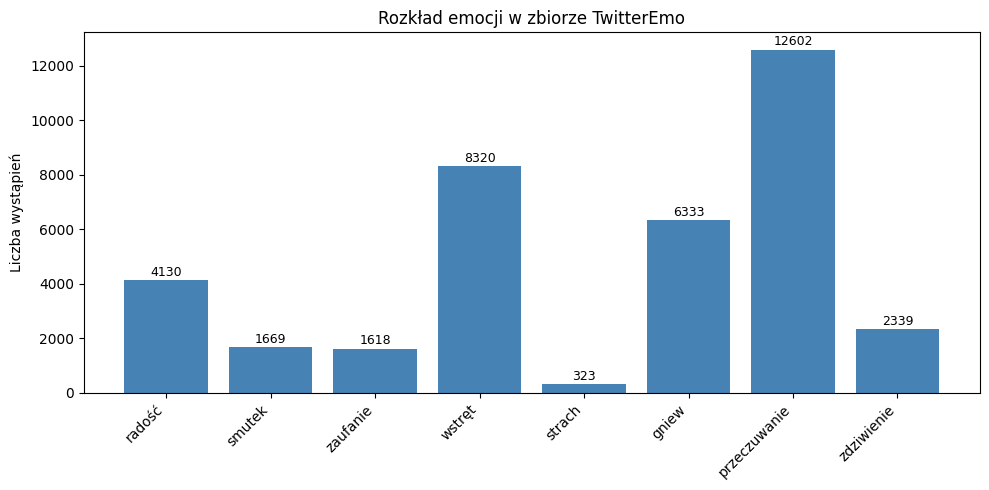

In [ ]:
label_counts = y.sum(axis=0).astype(int)

plt.figure(figsize=(10, 5))
bars = plt.bar(EMOTIONS, label_counts, color="steelblue")
plt.title("Rozkład emocji w zbiorze TwitterEmo")
plt.ylabel("Liczba wystąpień")
plt.xticks(rotation=45, ha="right")

# wartości nad słupkami
for bar, count in zip(bars, label_counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             str(count), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

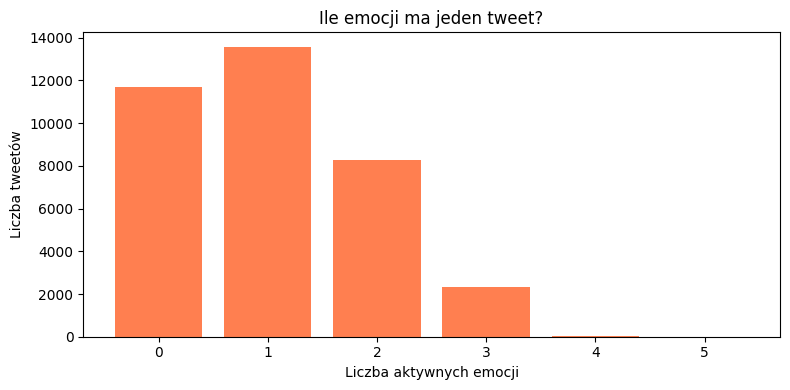

Tweetów bez żadnej emocji: 11688
Tweetów z ≥2 emocjami: 10656


In [ ]:
labels_per_tweet = y.sum(axis=1).astype(int)

plt.figure(figsize=(8, 4))
counts = pd.Series(labels_per_tweet).value_counts().sort_index()
plt.bar(counts.index, counts.values, color="coral")
plt.title("Ile emocji ma jeden tweet?")
plt.xlabel("Liczba aktywnych emocji")
plt.ylabel("Liczba tweetów")
plt.xticks(range(0, int(labels_per_tweet.max()) + 1))
plt.tight_layout()
plt.show()

print("Tweetów bez żadnej emocji:", (labels_per_tweet == 0).sum())
print("Tweetów z ≥2 emocjami:", (labels_per_tweet >= 2).sum())

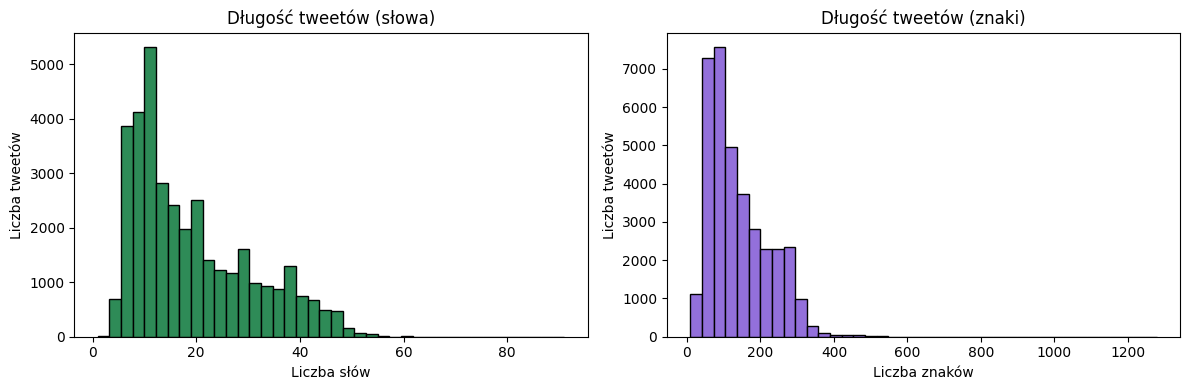

Średnia długość (słowa): 19.0
Mediana długości (słowa): 15.0
Max słów: 91


In [ ]:
text_lengths = [len(t.split()) for t in texts]  # liczba słów
char_lengths = [len(t) for t in texts]          # liczba znaków

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(text_lengths, bins=40, color="seagreen", edgecolor="black")
axes[0].set_title("Długość tweetów (słowa)")
axes[0].set_xlabel("Liczba słów")
axes[0].set_ylabel("Liczba tweetów")

axes[1].hist(char_lengths, bins=40, color="mediumpurple", edgecolor="black")
axes[1].set_title("Długość tweetów (znaki)")
axes[1].set_xlabel("Liczba znaków")
axes[1].set_ylabel("Liczba tweetów")

plt.tight_layout()
plt.show()

print(f"Średnia długość (słowa): {np.mean(text_lengths):.1f}")
print(f"Mediana długości (słowa): {np.median(text_lengths):.1f}")
print(f"Max słów: {max(text_lengths)}")

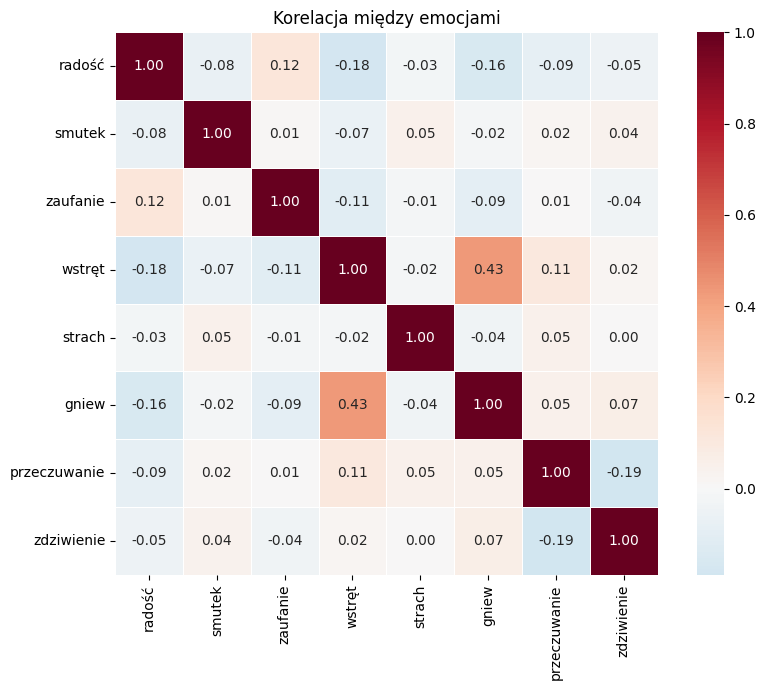

In [ ]:
corr = pd.DataFrame(y, columns=EMOTIONS).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5)
plt.title("Korelacja między emocjami")
plt.tight_layout()
plt.show()

In [ ]:
# pokazanie 5 tweetów, które mają ≥ 2 emocje
multi_idx = np.where(labels_per_tweet >= 2)[0][:5]

for i in multi_idx:
    active = [EMOTIONS[j] for j in range(8) if y[i, j] == 1]
    print(f"Tekst: {texts[i]}")
    print(f"Emocje: {active}")
    print("-" * 60)

Tekst: @anonymized_account Ten kto go zaprosił życzy dobrze przede wszystkim sobie a co by nie mówić to za takiego Bońka trochę przytuli z reklam.
Emocje: ['wstręt', 'gniew']
------------------------------------------------------------
Tekst: @anonymized_account I się tumanie zdziwisz. Obiecaj że jak większość bedze chciala Unii to wyjedziesz na Białoruś
Emocje: ['wstręt', 'gniew']
------------------------------------------------------------
Tekst: @anonymized_account Był tam też pan, który na pytania o łamanie Konstytucji, nie bardzo miał co odpowiedzieć, ale za to dodał, z wielkim przekonaniem, że oni szkalują nas w Brukseli      Przekazy żywcem z tvpis
Emocje: ['wstręt', 'gniew']
------------------------------------------------------------
Tekst: @anonymized_account Wielu z nas wiedziało już od wielu lat, że zmierzamy do totalnego upadku. Niestety jest nas, świadomych za mało. Myślę, że jednym z przejawów dalszego upadku będzie popadnięcie Europy i świata w autorytaryzmy. Każdy z na

## PoC:

In [ ]:
### 1. Przygotowanie małej próbki + podział

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, hamming_loss
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
from tqdm.auto import tqdm

# stałe
EMOTIONS = ["radość", "smutek", "zaufanie", "wstręt", "strach", "gniew", "przeczuwanie", "zdziwienie"]
SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)

# dane
texts = list(dataset["train"]["tekst"])
y = np.stack([dataset["train"][emo] for emo in EMOTIONS], axis=1).astype(np.float32)

# MAŁA PRÓBKA do PoC (np. 2000 przykładów) – żeby było szybko
N_SAMPLE = 2000
idx = np.random.choice(len(texts), N_SAMPLE, replace=False)
texts_s = [texts[i] for i in idx]
y_s = y[idx]

# podział 70/15/15 na małej próbce
train_texts, temp_texts, y_train, y_temp = train_test_split(
    texts_s, y_s, test_size=0.3, random_state=SEED
)
val_texts, test_texts, y_val, y_test = train_test_split(
    temp_texts, y_temp, test_size=0.5, random_state=SEED
)

print(f"Train: {len(train_texts)}, Val: {len(val_texts)}, Test: {len(test_texts)}")

### 2. Dataset + DataLoader

class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.float)
        }

MODEL_NAME = "allegro/herbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_ds = EmotionDataset(train_texts, y_train, tokenizer)
val_ds   = EmotionDataset(val_texts,   y_val,   tokenizer)
test_ds  = EmotionDataset(test_texts,  y_test,  tokenizer)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=32)
test_loader  = DataLoader(test_ds,  batch_size=32)

### 3. Model HerBERT z 8 wyjściami (multi-label)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=8,
    problem_type="multi_label_classification"   # ważne!
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print("Urządzenie:", device)

### 4. Trening (krótki – 2–3 epoki na PoC)

optimizer = AdamW(model.parameters(), lr=2e-5)
num_epochs = 2
num_training_steps = len(train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=0, num_training_steps=num_training_steps
)

loss_fn = torch.nn.BCEWithLogitsLoss()

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs.logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1} – train loss: {avg_loss:.4f}")

### 5. Predykcja na przykładowym wpisie + multi-label

def predict_emotions(text, model, tokenizer, threshold=0.5):
    model.eval()
    encoding = tokenizer(
        text, truncation=True, padding="max_length",
        max_length=128, return_tensors="pt"
    )
    with torch.no_grad():
        outputs = model(
            input_ids=encoding["input_ids"].to(device),
            attention_mask=encoding["attention_mask"].to(device)
        )
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]

    results = {emo: float(p) for emo, p in zip(EMOTIONS, probs)}
    active = [emo for emo, p in results.items() if p >= threshold]
    return results, active

# przykładowy tweet
example = "No pięknie, znów korki i spóźnię się do pracy. Idealnie."
probs, active = predict_emotions(example, model, tokenizer)

print("Tekst:", example)
print("\nPrawdopodobieństwa:")
for emo, p in probs.items():
    print(f"  {emo:15s}: {p:.3f}")
print("\nPrzypisane emocje (threshold=0.5):", active)

### 6. Pierwsze metryki na zbiorze testowym

def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].cpu().numpy()

            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs >= 0.5).astype(int)

            all_preds.append(preds)
            all_labels.append(labels)

    y_true = np.vstack(all_labels)
    y_pred = np.vstack(all_preds)

    micro = f1_score(y_true, y_pred, average="micro", zero_division=0)
    macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    ham   = hamming_loss(y_true, y_pred)

    per_emo = f1_score(y_true, y_pred, average=None, zero_division=0)

    return micro, macro, ham, per_emo

micro, macro, ham, per_emo = evaluate(model, test_loader)

print(f"micro-F1   : {micro:.4f}")
print(f"macro-F1   : {macro:.4f}")
print(f"Hamming    : {ham:.4f}")
print("\nF1 per emocja:")
for emo, f1 in zip(EMOTIONS, per_emo):
    print(f"  {emo:15s}: {f1:.3f}")

Train: 1400, Val: 300, Test: 300


config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/907k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/556k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/129 [00:00<?, ?B/s]

... (7 outputs left out)

Epoch 1:   0%|          | 0/88 [00:00<?, ?it/s]

Epoch 1 – train loss: 0.3897


Epoch 2:   0%|          | 0/88 [00:00<?, ?it/s]

Epoch 2 – train loss: 0.3158
Tekst: No pięknie, znów korki i spóźnię się do pracy. Idealnie.

Prawdopodobieństwa:
  radość         : 0.263
  smutek         : 0.090
  zaufanie       : 0.087
  wstręt         : 0.079
  strach         : 0.036
  gniew          : 0.085
  przeczuwanie   : 0.224
  zdziwienie     : 0.096

Przypisane emocje (threshold=0.5): []
micro-F1   : 0.2704
macro-F1   : 0.0964
Hamming    : 0.1192

F1 per emocja:
  radość         : 0.000
  smutek         : 0.000
  zaufanie       : 0.000
  wstręt         : 0.349
  strach         : 0.000
  gniew          : 0.000
  przeczuwanie   : 0.422
  zdziwienie     : 0.000


1. Przygotowanie małej próbki + podział

In [ ]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, hamming_loss
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
from tqdm.auto import tqdm

# stałe
EMOTIONS = ["radość", "smutek", "zaufanie", "wstręt", "strach", "gniew", "przeczuwanie", "zdziwienie"]
SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)

# dane
texts = list(dataset["train"]["tekst"])
y = np.stack([dataset["train"][emo] for emo in EMOTIONS], axis=1).astype(np.float32)

# MAŁA PRÓBKA do PoC (np. 2000 przykładów) – żeby było szybko
N_SAMPLE = 2000
idx = np.random.choice(len(texts), N_SAMPLE, replace=False)
texts_s = [texts[i] for i in idx]
y_s = y[idx]

# podział 70/15/15 na małej próbce
train_texts, temp_texts, y_train, y_temp = train_test_split(
    texts_s, y_s, test_size=0.3, random_state=SEED
)
val_texts, test_texts, y_val, y_test = train_test_split(
    temp_texts, y_temp, test_size=0.5, random_state=SEED
)

print(f"Train: {len(train_texts)}, Val: {len(val_texts)}, Test: {len(test_texts)}")

Train: 1400, Val: 300, Test: 300


2. Dataset + DataLoader

In [ ]:
class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.float)
        }

MODEL_NAME = "allegro/herbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_ds = EmotionDataset(train_texts, y_train, tokenizer)
val_ds   = EmotionDataset(val_texts,   y_val,   tokenizer)
test_ds  = EmotionDataset(test_texts,  y_test,  tokenizer)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=32)
test_loader  = DataLoader(test_ds,  batch_size=32)

config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/907k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/556k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/129 [00:00<?, ?B/s]

3. Model HerBERT z 8 wyjściami (multi-label)

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=8,
    problem_type="multi_label_classification"   # ważne!
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print("Urządzenie:", device)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allegro/herbert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.sso.sso_relationship.weight            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.sso.sso_relationship.bias              | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

Urządzenie: cpu


4. Trening (krótki – 2–3 epoki na PoC)

In [ ]:
optimizer = AdamW(model.parameters(), lr=2e-5)
num_epochs = 2
num_training_steps = len(train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=0, num_training_steps=num_training_steps
)

loss_fn = torch.nn.BCEWithLogitsLoss()

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs.logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1} – train loss: {avg_loss:.4f}")

Epoch 1:   0%|          | 0/88 [00:00<?, ?it/s]

5. Predykcja na przykładowym wpisie + multi-label

In [ ]:
def predict_emotions(text, model, tokenizer, threshold=0.5):
    model.eval()
    encoding = tokenizer(
        text, truncation=True, padding="max_length",
        max_length=128, return_tensors="pt"
    )
    with torch.no_grad():
        outputs = model(
            input_ids=encoding["input_ids"].to(device),
            attention_mask=encoding["attention_mask"].to(device)
        )
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]

    results = {emo: float(p) for emo, p in zip(EMOTIONS, probs)}
    active = [emo for emo, p in results.items() if p >= threshold]
    return results, active

# przykładowy tweet
example = "No pięknie, znów korki i spóźnię się do pracy. Idealnie."
probs, active = predict_emotions(example, model, tokenizer)

print("Tekst:", example)
print("\nPrawdopodobieństwa:")
for emo, p in probs.items():
    print(f"  {emo:15s}: {p:.3f}")
print("\nPrzypisane emocje (threshold=0.5):", active)

6. Pierwsze metryki na zbiorze testowym

In [ ]:
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].cpu().numpy()

            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs >= 0.5).astype(int)

            all_preds.append(preds)
            all_labels.append(labels)

    y_true = np.vstack(all_labels)
    y_pred = np.vstack(all_preds)

    micro = f1_score(y_true, y_pred, average="micro", zero_division=0)
    macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    ham   = hamming_loss(y_true, y_pred)

    per_emo = f1_score(y_true, y_pred, average=None, zero_division=0)

    return micro, macro, ham, per_emo

micro, macro, ham, per_emo = evaluate(model, test_loader)

print(f"micro-F1   : {micro:.4f}")
print(f"macro-F1   : {macro:.4f}")
print(f"Hamming    : {ham:.4f}")
print("\nF1 per emocja:")
for emo, f1 in zip(EMOTIONS, per_emo):
    print(f"  {emo:15s}: {f1:.3f}")

###7. Przykład wskazania kilku emocji

In [ ]:
example = "Cieszę się z awansu i nowej roli, ale jednocześnie czuję paniczny strach i ogromny stres, czy sobie poradzę."

#setting threshold to 0.3 to test values and emotions

probs, active = predict_emotions(example, model, tokenizer, threshold=0.3)

if len(active) > 1:
    print(model, f"\nSukces! Model przypisał wiele emocji jednocześnie: {active}")
else:
    print(f"\nPrzypisano emocje: {active}")